# Inter-Index Impact on Stock Markets

Do the US (S&P 500), UK (FTSE 100), Japan (Nikkei 225) and India (NIFTY 50) markets move each other, and can one market's returns be explained or **forecast** from the others?

The logic lives in the `interindex/` package. This notebook walks through it step by step. To reproduce every table and figure in one go, run `python run_experiments.py`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from interindex.data import load_prices
from interindex.features import build_panel
from interindex.experiment import run
from interindex.models import all_models, Ridge, RecurrentModel

pd.set_option("display.precision", 3)

## 1. Data
Weekly OHLCV prices, April 2019 to October 2026, cached in `data/` so results are reproducible.

In [2]:
prices = load_prices()
{m: len(df) for m, df in prices.items()}

{'US': 394, 'UK': 394, 'Japan': 393, 'India': 394}

## 2. Features
Each market gets nine **scale-free** features: weekly return, RSI, slow stochastic %K/%D, MACD and its signal line (as % of price), Bollinger %B, gap to the 5-week EMA, and weekly range.

Raw price levels are left out on purpose. They trend over time, so the test period would hold values the model never saw during training. We keep only the weeks where all four markets traded.

In [3]:
panel = build_panel(prices)
print(panel.shape, panel.index.min().date(), "→", panel.index.max().date())
panel.filter(like="India_").head()

(374, 36) 2019-08-19 → 2026-10-12


,India_Return,India_RSI,India_StochK,India_StochD,India_MACD,India_MACD_Signal,India_BB_PctB,India_EMA_Gap,India_Range
Date,,,,,,,,,
2019-08-19,-1.977,26.028,19.321,18.771,-1.563,-0.707,-0.023,-2.166,4.707
2019-08-26,1.791,34.508,19.845,19.354,-1.626,-0.881,0.162,-0.276,3.494
2019-09-02,-0.699,32.895,20.178,19.781,-1.746,-1.059,0.151,-0.651,2.020
2019-09-09,1.185,38.139,26.536,22.186,-1.697,-1.177,0.264,0.350,1.757
2019-09-16,1.790,45.192,33.549,26.754,-1.486,-1.222,0.412,1.421,6.312


## 3. How closely are the markets linked?

In [4]:
rets = panel.filter(like="_Return").rename(columns=lambda c: c.split("_")[0])
rets.corr()

,US,UK,Japan,India
US,1.000,0.616,0.618,0.555
UK,0.616,1.000,0.523,0.529
Japan,0.618,0.523,1.000,0.485
India,0.555,0.529,0.485,1.000


Same-week correlations are high (0.49 to 0.62). Next, we check whether this week's return in one market predicts next week's return in another (rows: this week; columns: next week):

In [5]:
pd.DataFrame({b: {a: rets[a].corr(rets[b].shift(-1)) for a in rets} for b in rets})

,US,UK,Japan,India
US,-0.089,-0.028,0.002,0.063
UK,0.045,-0.031,0.097,0.124
Japan,-0.029,-0.038,-0.046,-0.023
India,0.006,-0.007,0.003,0.033


Every lead-lag correlation is close to zero (|r| ≤ 0.13). By the end of each week, the markets have already absorbed each other's news.

## 4. Models
Every experiment uses the same setup:
- **Chronological split:** train on Aug 2019 to Dec 2024 (278 weeks), test on Jan 2025 to Oct 2026 (93 weeks the models never see). The scaler is fit on training data only.
- **No leakage:** in the same-week task, the target market contributes *no* columns.
- **Baselines:** predict 0%, or predict the training-period average.
- **Models:**
  - Ridge regression
  - LSTM and GRU (32 units, dropout, early stopping, averaged over 5 seeds), using a 4-week input window
- **Metric:** out-of-sample R² against the training mean. Positive means the model beats the baseline.

### 4a. Same week: explain a market from the other three

In [6]:
rows, preds = [], {}
for target in ["US", "UK", "Japan", "India"]:
    others = [m for m in ["US", "UK", "Japan", "India"] if m != target]
    r, preds[target] = run(panel, target, others, "same_week", all_models())
    rows += r
same = pd.DataFrame(rows)
same.pivot(index="Target", columns="Model", values="R2_OOS")[["Mean", "Zero", "Ridge", "LSTM", "GRU"]]

Model,Mean,Zero,Ridge,LSTM,GRU
Target,,,,,
India,0.0,0.034,-0.009,0.097,0.087
Japan,0.0,-0.027,0.215,0.134,0.194
UK,0.0,-0.014,0.049,0.055,0.062
US,0.0,-0.020,0.305,0.267,0.320


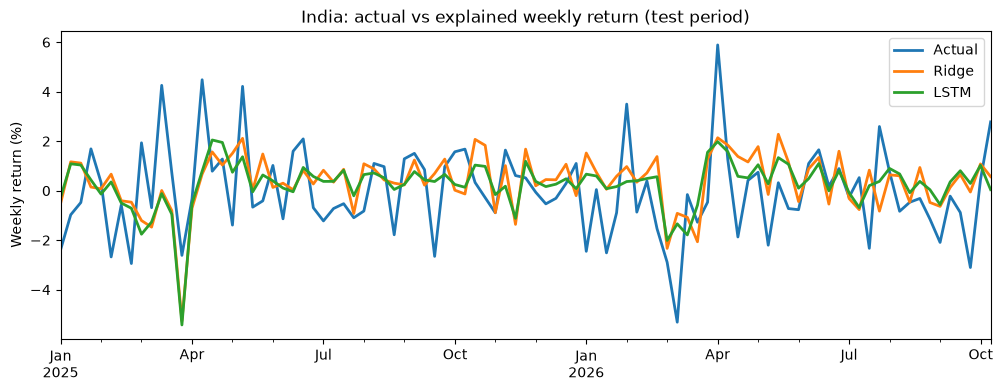

In [7]:
p = preds["India"]
ax = p[["Actual", "Ridge", "LSTM"]].plot(figsize=(12, 4), lw=2, title="India: actual vs explained weekly return (test period)")
ax.set_ylabel("Weekly return (%)");

### 4b. Which foreign markets explain India best?

In [8]:
from itertools import combinations
rows = []
for k in (1, 2, 3):
    for combo in combinations(["US", "UK", "Japan"], k):
        rows += run(panel, "India", list(combo), "same_week", [Ridge(), RecurrentModel("LSTM")])[0]
pd.DataFrame(rows).pivot(index="Inputs", columns="Model", values="R2_OOS").sort_values("LSTM", ascending=False)

Model,LSTM,Ridge
Inputs,,
UK + Japan,0.132,-2.577e-02
UK,0.099,1.000e-01
US + UK + Japan,0.097,-8.651e-03
US + UK,0.060,2.342e-04
Japan,0.020,-2.716e-01
US + Japan,-0.015,-1.681e-01
US,-0.094,-1.343e-01


### 4c. Next week: can we forecast?

In [9]:
rows = []
for target in ["US", "UK", "Japan", "India"]:
    rows += run(panel, target, ["US", "UK", "Japan", "India"], "next_week", all_models())[0]
nxt = pd.DataFrame(rows)
nxt.pivot(index="Target", columns="Model", values="R2_OOS")[["Mean", "Zero", "Ridge", "LSTM", "GRU"]]

Model,Mean,Zero,Ridge,LSTM,GRU
Target,,,,,
India,0.0,0.033,6.812e-04,-0.067,-0.295
Japan,0.0,-0.026,-1.024e-02,-0.079,-0.161
UK,0.0,-0.013,-6.072e-03,-0.074,-0.008
US,0.0,-0.020,2.158e-02,-0.006,-0.010


## 5. Conclusions
1. **The markets are linked within the same week.** Using only the other three markets, the models explain roughly 5–30% of a market's weekly return variance on unseen 2025–26 data. The US is the easiest market to explain, and the UK is the hardest.
2. **The links change over time.** Up to April 2024, the US alone explained about 28% of India's weekly moves. In 2025–26 it explains none of them (R² below 0), and the UK has become India's most useful single input. A model trained on one period doesn't fully carry over to the next.
3. **Next week's return can't be forecast.** At a weekly horizon, no model clearly beats predicting the average return, which is consistent with efficient markets.
4. **The deep models don't beat linear regression.** LSTM and GRU do no better than Ridge, even with about 280 training weeks.

## 6. Daily data, 12 markets, aligned by time zone

Weekly data blurs *when* information arrives. Using daily data, each market only gets credit for another market's close if that close happened **before it opened**, using conservative UTC trading hours from `interindex/markets.py`. For example, the US closes around 21:00 UTC and Japan opens at 00:00 UTC, so Japan's day *d* sees the US close from day *d−1*.

The full study (Granger tests on all 132 market pairs, a GRU model, rolling correlations) is in `run_global.py`. Below is a fast Ridge-only tour.

In [10]:
from interindex.daily import Aligner, load_daily
from interindex.markets import MARKETS, info_lag

aligner = Aligner(load_daily())
pd.DataFrame({m: {"region": k.region, "open UTC": k.open_utc, "close UTC": k.close_utc,
                  "sees US close from": "same day" if info_lag("US", m) == 0 else "previous day"}
              for m, k in MARKETS.items() if m != "US"}).T

,region,open UTC,close UTC,sees US close from
Canada,Americas,13.5,21.0,previous day
Brazil,Americas,13.0,21.0,previous day
UK,Europe,7.0,16.5,previous day
Germany,Europe,7.0,16.5,previous day
France,Europe,7.0,16.5,previous day
Japan,Asia,0.0,6.5,previous day
HongKong,Asia,1.5,8.0,previous day
China,Asia,1.5,7.0,previous day
Korea,Asia,0.0,6.5,previous day
Australia,Asia,-1.0,6.0,previous day


### 6a. Where the US move shows up: the opening gap vs the trading day

In [11]:
rows = {}
for t in ["Japan", "Korea", "HongKong", "China", "India", "Germany", "France"]:
    d = aligner.design(t)
    rows[t] = {"corr with gap": d["US"].corr(d["gap"]), "corr with intraday": d["US"].corr(d["intraday"])}
pd.DataFrame(rows).T.sort_values("corr with gap", ascending=False)

,corr with gap,corr with intraday
Japan,0.626,1.407e-01
Korea,0.560,-4.244e-02
India,0.497,-3.833e-02
HongKong,0.495,-6.322e-02
China,0.474,-8.312e-02
Germany,0.217,-6.419e-03
France,0.212,-3.384e-05


### 6b. Walk-forward forecasts with a significance test
The model is refit every January on all earlier data, then forecasts that whole year (2021 to 2026). A Diebold–Mariano test checks whether it beats the historical-mean forecast.

In [12]:
from interindex.walkforward import sequences, walk_forward, score

rows = []
for t in ["Japan", "Korea", "India", "Germany"]:
    d = aligner.design(t)
    for y_col in ["cc", "intraday"]:
        X, y, dates = sequences(d, [m for m in MARKETS if m != t], y_col)
        pred = walk_forward(X, y, dates, [Ridge()])
        rows.append({"Target": t, "Return": y_col, **score(pred, "Ridge")})
pd.DataFrame(rows).drop(columns="Sharpe_gross")

,Target,Return,R2_OOS,Direction_Acc,DM_stat,DM_p,N_test
0,Japan,cc,2.062e-01,0.641,4.554,2.628e-06,1417
1,Japan,intraday,5.842e-03,0.502,2.246,1.236e-02,1417
2,Korea,cc,1.036e-01,0.614,4.923,4.269e-07,1418
3,Korea,intraday,-3.004e-03,0.501,-0.848,8.019e-01,1418
4,India,cc,3.940e-02,0.568,3.006,1.324e-03,1433
5,India,intraday,-7.529e-05,0.514,-0.031,5.124e-01,1433
6,Germany,cc,3.958e-02,0.590,0.829,2.034e-01,1480
7,Germany,intraday,-9.218e-03,0.477,-2.654,9.960e-01,1480


### 6c. Conclusions from the daily study
- **The time-zone effect is real and significant.** The US close predicts the next Asian session's close-to-close return (walk-forward R² of 0.10–0.33 for Japan, Korea and Australia, Diebold–Mariano q < 0.001).
- **It isn't a free lunch.** Almost all of that predictability sits in the **opening gap**. Once Asian markets open, the US news is already priced in, and open-to-close returns are no more predictable than chance.
- Europe and the Americas, whose sessions overlap with the US, show little such lead-lag effect.